# 02 - Price Elasticity of Demand
**Topic:** Regression  |  **Reference:** "Price Elasticity of Demand Analysis with Python" (amanxai.com, Aug 2024)

**Question.** If a retailer changes the price of an item by 1%, by about how much does the quantity sold change? That ratio is the *price elasticity of demand* (PED).

**Reference method:** compute `pct_change()` of price and of quantity row by row and divide. **My method:** first check how the file is built, then estimate one elasticity with a log-log regression that compares each store-item *with itself* over time, and test whether a model that uses price predicts next week's sales better than one that ignores it.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
raw = pd.read_csv("../_data/ped.csv")
raw["week"] = raw["Fiscal_Week_ID"].str[-2:].astype(int)
print(raw.shape); raw.head(6)

(100000, 10)


,Index,Fiscal_Week_ID,Store_ID,Item_ID,Price,Item_Quantity,Sales_Amount_No_Discount,Sales_Amount,Competition_Price,week
0,0,2019-11,store_459,item_526,134.49,435,4716.74,11272.59,206.44,11
1,1,2019-11,store_459,item_526,134.49,435,4716.74,11272.59,158.01,11
2,2,2019-11,store_459,item_526,134.49,435,4716.74,11272.59,278.03,11
3,3,2019-11,store_459,item_526,134.49,435,4716.74,11272.59,222.66,11
4,4,2019-11,store_459,item_526,134.49,435,4716.74,11272.59,195.32,11
5,5,2019-11,store_459,item_526,134.49,435,4716.74,11272.59,108.75,11


## 2. Understand how the file is built (before computing anything)

In [2]:
key = ["week", "Store_ID", "Item_ID"]
print("rows:", len(raw), "| stores:", raw.Store_ID.nunique(), "| items:", raw.Item_ID.nunique(), "| weeks:", sorted(raw.week.unique()))
obs = raw.groupby(key + ["Price", "Item_Quantity"], as_index=False).agg(comp_price=("Competition_Price", "mean"), n_rows=("Index", "size"),
                                                                       sales=("Sales_Amount", "first"), sales_nd=("Sales_Amount_No_Discount", "first"))
print("distinct (store, item, week, price, quantity) observations:", len(obs))
print("raw rows per observation:", obs.n_rows.describe().round(1).to_dict())
print("distinct competitor prices inside one observation (mean):", raw.groupby(key+["Price","Item_Quantity"])["Competition_Price"].nunique().mean().round(1))
print("\nobservations per (store, item, week):", obs.groupby(key).size().value_counts().to_dict())
print("weeks observed per store-item:", obs.groupby(["Store_ID", "Item_ID"])["week"].nunique().value_counts().sort_index().to_dict())
# do the money columns agree with price x quantity?
print("\ncorr(Price*Qty, Sales_Amount_No_Discount) = %.3f" % np.corrcoef(obs.Price * obs.Item_Quantity, obs.sales_nd)[0, 1])
print("Sales_Amount > Sales_Amount_No_Discount in %.0f%% of observations (a discounted amount should not exceed the undiscounted one)" % ((obs.sales > obs.sales_nd).mean() * 100))

rows: 100000 | stores: 10 | items: 176 | weeks: [np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15)]
distinct (store, item, week, price, quantity) observations: 10000
raw rows per observation: {'count': 10000.0, 'mean': 10.0, 'std': 3.0, 'min': 2.0, '25%': 8.0, '50%': 10.0, '75%': 12.0, 'max': 20.0}
distinct competitor prices inside one observation (mean): 10.0

observations per (store, item, week): {1: 7650, 2: 1100, 3: 50}
weeks observed per store-item: {5: 1760}

corr(Price*Qty, Sales_Amount_No_Discount) = 0.104
Sales_Amount > Sales_Amount_No_Discount in 100% of observations (a discounted amount should not exceed the undiscounted one)


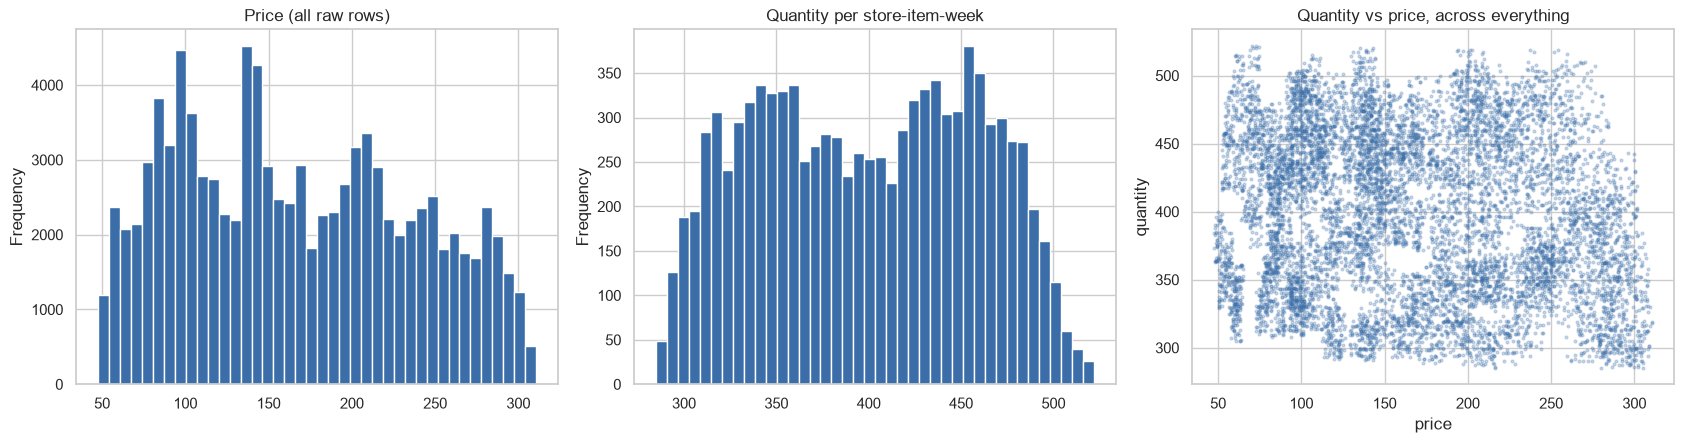

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
raw["Price"].plot.hist(bins=40, ax=ax[0], color="#3b6ea8"); ax[0].set_title("Price (all raw rows)")
obs["Item_Quantity"].plot.hist(bins=40, ax=ax[1], color="#3b6ea8"); ax[1].set_title("Quantity per store-item-week")
ax[2].scatter(obs["Price"], obs["Item_Quantity"], s=4, alpha=.25, color="#3b6ea8"); ax[2].set_title("Quantity vs price, across everything"); ax[2].set_xlabel("price"); ax[2].set_ylabel("quantity")
plt.tight_layout(); plt.show()

**What the file really contains.**
* 100,000 rows collapse to **10,000 distinct store-item-week observations**: each one is repeated about 10 times, and the only thing that changes between the copies is `Competition_Price`. The 100,000 rows are therefore not 100,000 independent facts.
* Every store-item is observed in exactly 5 weeks (10 stores x 176 items, 1,760 store-items). In 1,150 store-item-weeks there are 2-3 different price/quantity records.
* The money columns do not behave like their names: `Sales_Amount` is larger than `Sales_Amount_No_Discount` in 100% of observations, and `Price x Quantity` is almost uncorrelated with the no-discount sales figure (0.10). I therefore do not use either money column.
* Quantity stays inside a narrow band whatever the price is (right-hand scatter). This pattern is unusual for real shop data; the source does not document how the file was made, so I treat it as a practice file and not as evidence about a real retailer.

## 3. The reference method, replicated, on the raw file and on the de-duplicated file
Reference: group by store+item, `pct_change()` of Price and of Item_Quantity, `PED = %dQ / %dP`, drop infinite/NaN rows, average the rest.

             reference style (raw rows)  same formula, de-duplicated
rows in                      100000.000                    10000.000
rows kept                      8234.000                     8234.000
mean PED                         -0.461                       -0.334
median PED                        0.000                        0.000
share PED<0                       0.490                        0.490
min                           -1455.268                    -1455.268
max                            1127.614                     1458.971


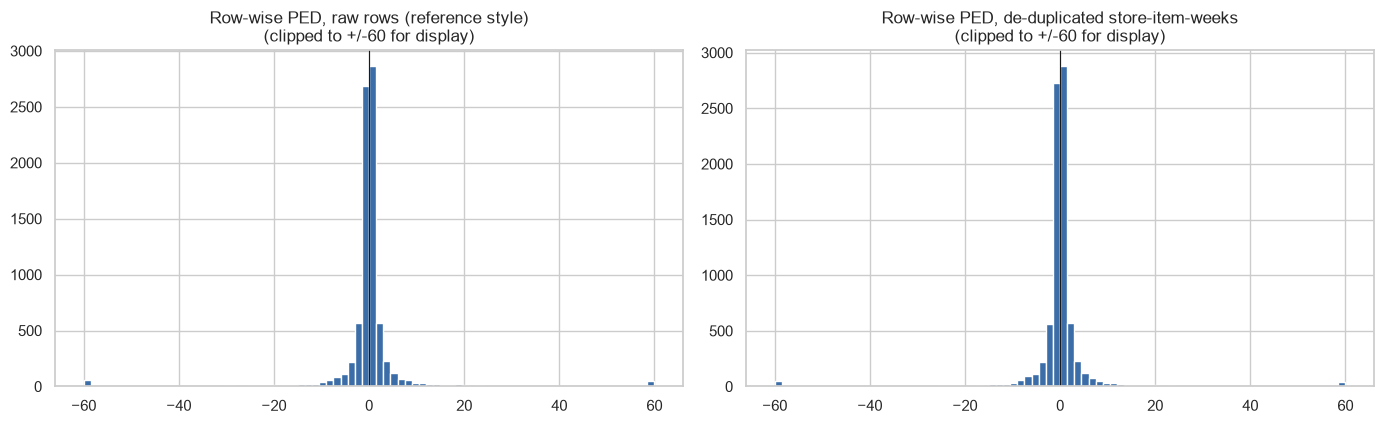

In [4]:
def ref_ped(frame, sort_cols=None):
    f = frame.copy()
    if sort_cols: f = f.sort_values(sort_cols)
    f["dP"] = f.groupby(["Store_ID", "Item_ID"])["Price"].pct_change()
    f["dQ"] = f.groupby(["Store_ID", "Item_ID"])["Item_Quantity"].pct_change()
    f["PED"] = f["dQ"] / f["dP"]
    n0 = len(f)
    f = f.replace([np.inf, -np.inf], np.nan).dropna(subset=["PED"])
    return f, n0

r_raw, n_raw = ref_ped(raw)                      # as the reference does: file order, duplicates included
r_obs, n_obs = ref_ped(obs, ["Store_ID", "Item_ID", "week"])   # one row per store-item-week, in time order
tab = pd.DataFrame({"rows in": [n_raw, n_obs], "rows kept": [len(r_raw), len(r_obs)],
                    "mean PED": [r_raw.PED.mean(), r_obs.PED.mean()], "median PED": [r_raw.PED.median(), r_obs.PED.median()],
                    "share PED<0": [(r_raw.PED < 0).mean(), (r_obs.PED < 0).mean()], "min": [r_raw.PED.min(), r_obs.PED.min()], "max": [r_raw.PED.max(), r_obs.PED.max()]},
                   index=["reference style (raw rows)", "same formula, de-duplicated"])
print(tab.round(3).T.to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for a, f, t in zip(ax, [r_raw, r_obs], ["raw rows (reference style)", "de-duplicated store-item-weeks"]):
    a.hist(f.PED.clip(-60, 60), bins=80, color="#3b6ea8"); a.axvline(0, color="k", lw=.8); a.set_title("Row-wise PED, " + t + "\n(clipped to +/-60 for display)")
plt.tight_layout(); plt.show()

**Reading it.**
* With the reference formula, only about 8% of the 100,000 rows survive (the rest have a price change of exactly zero, so the ratio is infinite or undefined).
* The result is very unstable: the **mean** is about -0.46 on the raw rows and -0.33 after removing the duplicate copies (the reference article reports about -0.35). Individual ratios run from about -1,455 to +1,459. The mean of numbers with tails like that is decided by a few extreme rows.
* The **median is about 0** and only **49% of the ratios are negative**: if demand fell when price rose, clearly more than half should be negative. Half-and-half is what pure noise looks like.
* So the reference conclusion "demand is slightly inelastic" is not supported by its own method on this file; the average is a product of the formula, not a measurement of price sensitivity.

## 4. My method: log-log regression with store-item fixed effects
Model: `log(Q) = a(store,item) + b*log(P) + c*log(competitor P) + week effects + error`.
* `b` is the elasticity: a 1% price change goes with a `b`% quantity change.
* `a(store,item)` gives every store-item its own baseline, so `b` is learned from how the *same* item changes over time, not from comparing cheap items with expensive ones.
* Standard errors are clustered by store-item.

In [5]:
d = obs.copy()
d["lq"] = np.log(d.Item_Quantity); d["lp"] = np.log(d.Price); d["lc"] = np.log(d.comp_price)
d["si"] = d.Store_ID + "|" + d.Item_ID
m_pool = smf.ols("lq ~ lp", d).fit(cov_type="cluster", cov_kwds={"groups": d["si"]})
m_fe = smf.ols("lq ~ lp + lc + C(week) + C(si)", d).fit(cov_type="cluster", cov_kwds={"groups": d["si"]})
rows = []
for name, m, terms in [("pooled (no fixed effects)", m_pool, ["lp"]), ("store-item fixed effects", m_fe, ["lp", "lc"])]:
    for t in terms:
        ci = m.conf_int().loc[t]
        rows.append([name, {"lp": "own price", "lc": "competitor price"}[t], m.params[t], ci[0], ci[1], m.pvalues[t]])
print(pd.DataFrame(rows, columns=["model", "term", "elasticity", "ci_low", "ci_high", "p_value"]).round(4).to_string(index=False))
print("within-item price variation: sd of log price after removing each store-item mean = %.3f (about %.1f%%)" % (
      (d.lp - d.groupby("si").lp.transform("mean")).std(), (d.lp - d.groupby("si").lp.transform("mean")).std() * 100))

                    model             term  elasticity  ci_low  ci_high  p_value
pooled (no fixed effects)        own price     -0.0460 -0.0598  -0.0322   0.0000
 store-item fixed effects        own price      0.0079 -0.0347   0.0505   0.7168
 store-item fixed effects competitor price     -0.0399 -0.0513  -0.0286   0.0000
within-item price variation: sd of log price after removing each store-item mean = 0.151 (about 15.1%)


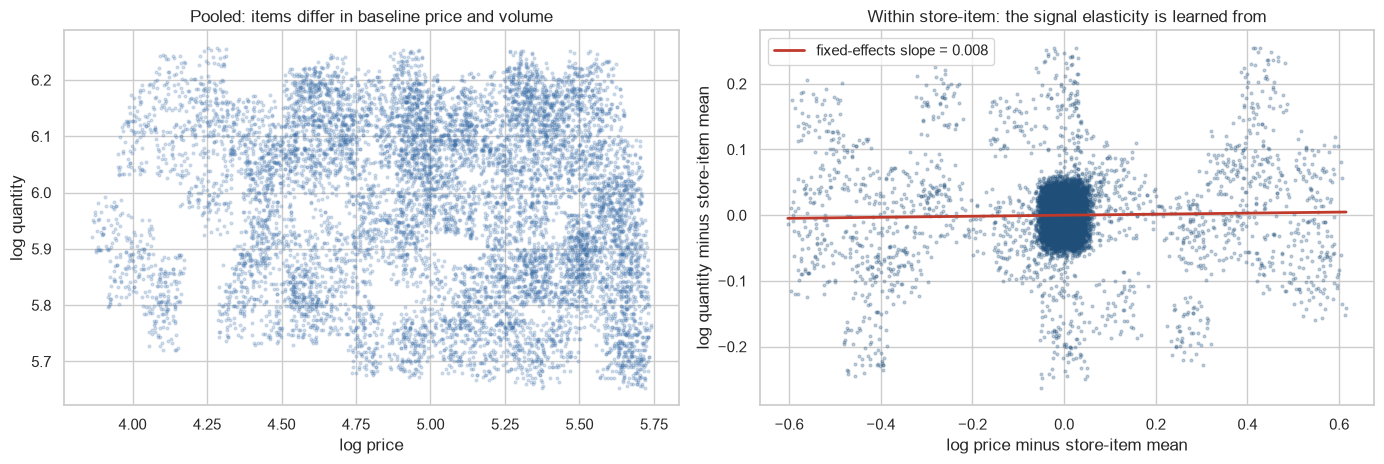

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].scatter(d.lp, d.lq, s=4, alpha=.2, color="#3b6ea8"); ax[0].set_xlabel("log price"); ax[0].set_ylabel("log quantity"); ax[0].set_title("Pooled: items differ in baseline price and volume")
dm = pd.DataFrame({"lp": d.lp - d.groupby("si").lp.transform("mean"), "lq": d.lq - d.groupby("si").lq.transform("mean")})
ax[1].scatter(dm.lp, dm.lq, s=4, alpha=.25, color="#1f4e79")
xs = np.linspace(dm.lp.min(), dm.lp.max(), 50); ax[1].plot(xs, m_fe.params["lp"] * xs, color="#c0392b", lw=2, label="fixed-effects slope = %.3f" % m_fe.params["lp"])
ax[1].set_xlabel("log price minus store-item mean"); ax[1].set_ylabel("log quantity minus store-item mean"); ax[1].set_title("Within store-item: the signal elasticity is learned from"); ax[1].legend()
plt.tight_layout(); plt.show()

**Reading it.**
* The pooled slope is slightly negative (-0.046) but this mixes cheap and expensive items, so it says little about what happens when *one* item's price moves.
* The fixed-effects estimate, which only compares an item with itself, is **+0.008, 95% interval -0.035 to +0.051 (p = 0.72)**. The data give no evidence that weekly price changes move the quantity sold, and the interval is narrow enough to rule out any strong effect either way (for example -1).
* The competitor-price coefficient is small, negative and statistically different from zero (-0.040). Higher competitor prices going with *lower* own sales is the opposite of what theory says for substitutes, and the competitor price here is an average of about 10 inconsistent copies, so I would not use it for decisions.
* The right-hand plot shows the shape: a dense cloud at "no price change" and a few clusters at large price jumps, with quantity inside the same band in both.

## 5. Does elasticity differ between stores or price tiers?
Same fixed-effects model, interacted with store and with the item's price tercile. With only about five weeks per store-item, subgroup estimates are noisy: look at the interval widths, not only the points.

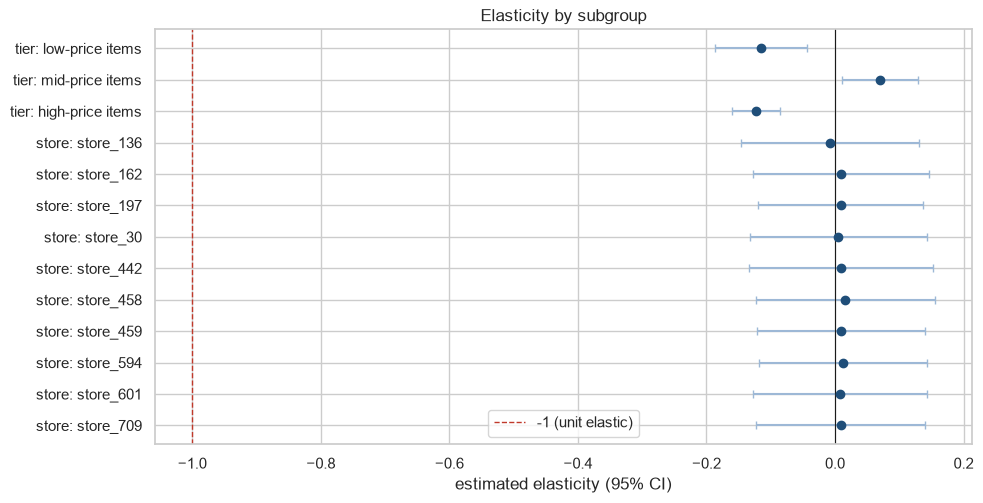

   by            group  elasticity     lo     hi    n
 tier  low-price items      -0.115 -0.187 -0.044 3400
 tier  mid-price items       0.070  0.011  0.130 3300
 tier high-price items      -0.123 -0.161 -0.086 3300
store        store_136      -0.008 -0.147  0.131 1000
store        store_162       0.009 -0.128  0.146 1000
store        store_197       0.009 -0.120  0.137 1000
store         store_30       0.005 -0.133  0.142 1000
store        store_442       0.009 -0.134  0.152 1000
store        store_458       0.016 -0.123  0.155 1000
store        store_459       0.009 -0.122  0.140 1000
store        store_594       0.012 -0.119  0.144 1000
store        store_601       0.008 -0.127  0.144 1000
store        store_709       0.009 -0.123  0.140 1000


In [7]:
d["tier"] = pd.qcut(d.groupby("Item_ID").Price.transform("mean"), 3, labels=["low-price items", "mid-price items", "high-price items"])
out = []
for g, s in d.groupby("tier", observed=True):
    mm = smf.ols("lq ~ lp + lc + C(week) + C(si)", s).fit(cov_type="cluster", cov_kwds={"groups": s["si"]})
    ci = mm.conf_int().loc["lp"]; out.append(["tier", g, mm.params["lp"], ci[0], ci[1], len(s)])
for g, s in d.groupby("Store_ID"):
    mm = smf.ols("lq ~ lp + lc + C(week) + C(si)", s).fit(cov_type="cluster", cov_kwds={"groups": s["si"]})
    ci = mm.conf_int().loc["lp"]; out.append(["store", g, mm.params["lp"], ci[0], ci[1], len(s)])
sub = pd.DataFrame(out, columns=["by", "group", "elasticity", "lo", "hi", "n"])
fig, ax = plt.subplots(figsize=(10, 5.2))
yy = np.arange(len(sub))[::-1]
ax.errorbar(sub.elasticity, yy, xerr=[sub.elasticity - sub.lo, sub.hi - sub.elasticity], fmt="o", color="#1f4e79", ecolor="#9db8d6", capsize=3)
ax.axvline(0, color="k", lw=.8); ax.axvline(-1, color="#c0392b", ls="--", lw=1, label="-1 (unit elastic)")
ax.set_yticks(yy); ax.set_yticklabels(sub.by + ": " + sub.group.astype(str)); ax.set_xlabel("estimated elasticity (95% CI)"); ax.legend(); ax.set_title("Elasticity by subgroup")
plt.tight_layout(); plt.show()
print(sub.round(3).to_string(index=False))

**Reading it.** The store estimates are all within about +/-0.02 of zero with intervals roughly +/-0.13 wide: no store looks different. The three price tiers show small estimates (-0.12, +0.07, -0.12) with intervals that exclude zero but sit far from -1, and the middle tier has the opposite sign. With three tiers and 13 subgroup tests, a few such differences can appear by chance, and the economic size is tiny. I would not claim that price tiers differ.

## 6. Does knowing the price help predict sales? A forward-in-time test
Train on weeks 11-14, test on week 15 (the future). Baselines: predict each store-item's training average; add last week's quantity; add price and competitor price. Metric: RMSE of log quantity (about the percentage error).

In [8]:
d = d.sort_values(["si", "week"]).reset_index(drop=True)
d["lq_prev"] = d.groupby("si").lq.shift(1)
d["lp_prev"] = d.groupby("si").lp.shift(1)
d["dlp"] = d.lp - d.lp_prev
tr, te = d[d.week <= 14].copy(), d[d.week == 15].copy()
te = te[te.si.isin(tr.si)].dropna(subset=["lq_prev"])
tr = tr.dropna(subset=["lq_prev"])
def rmse(p): return float(np.sqrt(mean_squared_error(te.lq, p)))
base_mean = te.si.map(tr.groupby("si").lq.mean())
base_last = te.lq_prev
m_a = smf.ols("lq ~ C(si)", tr).fit()
m_b = smf.ols("lq ~ lp + lc + C(si)", tr).fit()
feats = ["lp", "lc", "lq_prev", "lp_prev", "dlp", "week"]
for df_ in (tr, te):
    df_["item_code"] = df_.Item_ID.str.split("_").str[1].astype(int); df_["store_code"] = df_.Store_ID.str.split("_").str[1].astype(int)
F = feats + ["item_code", "store_code"]
hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_leaf_nodes=15, min_samples_leaf=40, random_state=0).fit(tr[F], tr.lq)
F_noprice = ["lq_prev", "week", "item_code", "store_code"]
hgb0 = HistGradientBoostingRegressor(max_iter=300, learning_rate=.05, max_leaf_nodes=15, min_samples_leaf=40, random_state=0).fit(tr[F_noprice], tr.lq)
res = pd.DataFrame({"model": ["store-item average (ignores price)", "last week's quantity", "fixed effects + price + competitor price", "gradient boosting WITHOUT any price feature", "gradient boosting (price, competitor, lags)"],
                    "RMSE_log_qty": [rmse(base_mean), rmse(base_last), rmse(m_b.predict(te)), rmse(hgb0.predict(te[F_noprice])), rmse(hgb.predict(te[F]))]})
print("train rows", len(tr), "| test rows", len(te)); print(res.round(4).to_string(index=False))
print("sd of log quantity in the test week (the error of a constant prediction): %.4f" % te.lq.std())

train rows 6240 | test rows 2000
                                      model  RMSE_log_qty
         store-item average (ignores price)        0.0570
                       last week's quantity        0.0986
   fixed effects + price + competitor price        0.0568
gradient boosting WITHOUT any price feature        0.0505
gradient boosting (price, competitor, lags)        0.0468
sd of log quantity in the test week (the error of a constant prediction): 0.1506


**Reading it (one test week, 2,000 rows: indicative, not definitive).**
* A model that ignores price (store-item average, RMSE 0.0570) is as good as the linear fixed-effects model with price (0.0568): in the linear model price adds nothing, consistent with the elasticity of about zero.
* "Same as last week" is worse (0.0986): week-to-week quantity is noisy, so last week's value is a poor predictor.
* Gradient boosting scores best (0.0468). The ablation matters: **without any price feature it scores 0.0505**, so most of its edge comes from the quantity lag, item and store identity, and the price features add a further ~7% reduction in error. This is a prediction gain in one test week and does not establish a causal price effect.
* Everything beats a constant prediction (0.1506) because item identity explains most of the variation.

## 7. A what-if curve for one item (with the limits stated)
Using the fixed-effects elasticity: how would quantity and revenue move if the price moved +/-15%? This extrapolates a *small-change* estimate; observed weekly price moves are only a few percent, so large moves are outside the evidence.

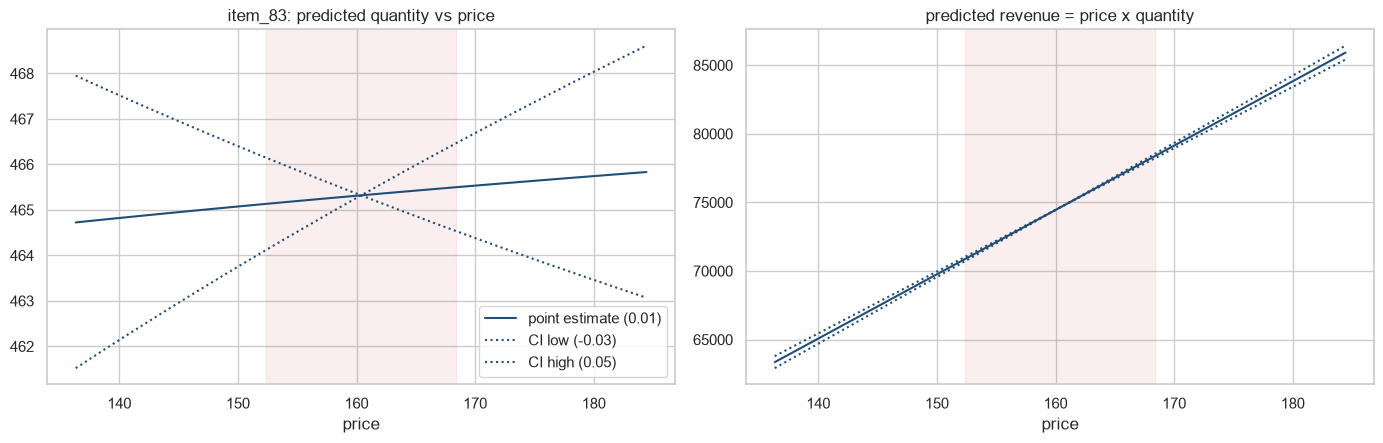

observed weekly price moves for this item: sd = 3.9% (shaded band = +/-5% around the average price)


In [9]:
b = m_fe.params["lp"]; lo, hi = m_fe.conf_int().loc["lp"]
item = d.groupby("Item_ID").Price.mean().sub(d.Price.median()).abs().idxmin()
s = d[d.Item_ID == item]; p0, q0 = s.Price.mean(), s.Item_Quantity.mean()
pr = np.linspace(.85, 1.15, 31)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for bb, ls, lab in [(b, "-", "point estimate"), (lo, ":", "CI low"), (hi, ":", "CI high")]:
    q = q0 * pr ** bb
    ax[0].plot(pr * p0, q, ls, color="#1f4e79", label=f"{lab} ({bb:.2f})"); ax[1].plot(pr * p0, pr * p0 * q, ls, color="#1f4e79")
ax[0].set_title(f"{item}: predicted quantity vs price"); ax[0].set_xlabel("price"); ax[0].legend(); ax[1].set_title("predicted revenue = price x quantity"); ax[1].set_xlabel("price")
for a in ax: a.axvspan(p0 * .95, p0 * 1.05, color="#c0392b", alpha=.08)
plt.tight_layout(); plt.show()
print("observed weekly price moves for this item: sd = %.1f%% (shaded band = +/-5%% around the average price)" % (s.lp.diff().std() * 100))

**Reading it.** With an estimated elasticity of about zero, the model says quantity hardly moves and revenue rises almost one-for-one with price, so the curve would "recommend" ever higher prices. That is a warning about what a near-zero estimate can and cannot do: weekly moves for this item are only about 4%, so anything beyond the shaded band is extrapolation, and the estimate has never seen demand collapse. I would not use this curve to set prices.

## 8. Save for the app

In [10]:
meta = {"elasticity": float(m_fe.params["lp"]), "ci": [float(lo), float(hi)], "cross_price": float(m_fe.params["lc"]),
        "items": {i: {"price_mean": float(g.Price.mean()), "qty_mean": float(g.Item_Quantity.mean()), "price_min": float(g.Price.min()), "price_max": float(g.Price.max())} for i, g in d.groupby("Item_ID")},
        "rmse": res.set_index("model").RMSE_log_qty.round(4).to_dict()}
json.dump(meta, open("model/meta.json", "w"), indent=1)
joblib.dump({"params": m_fe.params[["lp", "lc"]].to_dict(), "model": "log-log fixed effects"}, "model/elasticity_model.joblib")
joblib.dump(hgb, "model/demand_hgb.joblib")
print(os.listdir("model"))

['demand_hgb.joblib', 'elasticity_model.joblib', 'meta.json']


## 9. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Unit of analysis | 100,000 raw rows (about 10 copies each) | 10,000 distinct store-item-weeks |
| Estimate | mean of row-wise %dQ/%dP ratios (about -0.35 reported; -0.46 / -0.33 when I re-ran it) | log-log regression with store-item and week effects: **+0.008 (95% CI -0.035 to +0.051)** |
| Uncertainty | none | clustered standard errors, subgroup intervals |
| Validation | none | forward-in-time hold-out week, with a no-price ablation |
| Conclusion | "demand is slightly inelastic" | no detectable price effect in this file; revenue what-if is not decision-grade |

**What I learned.**
1. Check how a file is built before computing anything: the biggest result here (the duplicated rows and inconsistent money columns) came from `groupby`/`nunique`, not from a model.
2. A ratio of two noisy percentage changes is a poor estimator; a regression with a stated interval is much more honest.
3. "Not significant" is a finding: it says the data cannot support a pricing decision, not that elasticity is exactly zero.

**Limits.** Five weeks per item; competitor price is an average of inconsistent copies; no cost data; a synthetic-looking file. **Next step:** a dataset with real promotions or price experiments, where the price changes are large and not chosen by the sellers.